## Minutes using AI Relative to Time Spent Procrasinating

**Graph Type:** Parallel Coordinate Plot

**Description:** This parallel coordinate plot compares minutes of AI used with time spent procrastinating with each line representing one student and each axis representing a different type of procrastination: sleeping/napping, hanging out with friends, completing easier or other assignments, watching shows/movies, social media (Instagram, TikTok, etc.), and gaming. Lines that rise or fall together across the axis show which kinds of procrastination tend to go along with heavier or lighter AI use. Where lines cluster tightly, a pattern is shared across students. Where they spread out or cross, the relationship is weaker or varies by person.

**Hypothesis:** Students who use AI for more minutes spend less time procrastinating overall, and certain types of procrastination, such as completing easier assignments, are less likely to use as much AI as others, such as gaming or social media.

**Conclusion:** There is no clear relationship between how many minutes students used AI and how they procrastinate. AI usage does not appear to depend on how a student procrastinates, but social media is the dominant procrastination activity across all AI usage levels

## Imports


In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

survey_df = pd.read_csv("../../data/uncleaned_data.csv")

## Data Cleaning

Here I pulled data from multiple different sources. Specifically the survey questions that inquired about different amounts of procrasinations from working on other to assignments to gaming or watching shows. Afterwards, I separated them into different columns and turned the responses into numerical values I could plot on the graphs. I then pulled data from how many minutes of AI used in the last 7 days to create the buckets for in increments of 50 minutes. For the last touch, I added an overall total procrasination column at the end to track overall procrasination. I did additionally remove any responses that either did not answer the survey questions or had minutes of AI use that seemed like outliers (answers over 400 minutes).

In [ ]:
proc_df = survey_df.loc[:, "If you procrastinate, what do you typically spend your time doing?  [Sleeping/Napping]":
                           "If you procrastinate, what do you typically spend your time doing?  [Gaming]"].copy()
proc_df.columns = ["Sleeping/\nNapping", "Hanging Out\nwith Friends", "Easier\nAssignments", "Shows/\nMovies", "Social\nMedia", "Gaming"]

minutes_col = [c for c in survey_df.columns if c.startswith("In the past 7 days, approximately how many minutes")][0]
ai_col = "Average Minutes\nof AI Used"
raw_ai_col = "raw_minutes"
proc_df[raw_ai_col] = pd.to_numeric(survey_df[minutes_col], errors="coerce")

# Convert the answers into values 1 to 5
scale = {"Never": 1, "Rarely": 2, "Sometimes": 3, "Often": 4, "Always": 5}
procrastination_types = [c for c in proc_df.columns if c != raw_ai_col]
for col in procrastination_types:
    proc_df[col] = proc_df[col].map(scale)

# Remove rows with blank values
proc_df = proc_df.dropna()


ai_cutoff = 400
n_before = len(proc_df)
proc_df = proc_df[proc_df[raw_ai_col] <= ai_cutoff]
n_removed = n_before - len(proc_df)


overall_col = "Overall\nProcrastination"
proc_df[overall_col] = proc_df[procrastination_types].mean(axis=1)


bucket_size = 50
edges = list(range(0, ai_cutoff + 1, bucket_size))
bucket_labels = [f"{lo + 1}-{hi} min" for lo, hi in zip(edges[:-1], edges[1:])]
proc_df["bucket"] = pd.cut(proc_df[raw_ai_col], bins=edges, labels=bucket_labels, include_lowest=True)


value_cols = [raw_ai_col] + procrastination_types + [overall_col]
bucket_means = proc_df.groupby("bucket", observed=True)[value_cols].mean()
bucket_n = proc_df.groupby("bucket", observed=True).size()
bucket_means = bucket_means.rename(columns={raw_ai_col: ai_col})


ai_ticks = [0, 100, 200, 300, 400]

scaled_df = pd.DataFrame(index=bucket_means.index)
scaled_df[ai_col] = bucket_means[ai_col] / ai_cutoff
for col in procrastination_types + [overall_col]:
    scaled_df[col] = (bucket_means[col] - 1) / 4

columns = [ai_col] + procrastination_types + [overall_col]
x = np.arange(len(columns))

# One color per bucket (light to dark as AI use goes up)
cmap = plt.cm.viridis
bucket_colors = {b: cmap(0.05 + 0.85 * i / (len(bucket_labels) - 1)) for i, b in enumerate(bucket_labels)}


## Creating the Graph

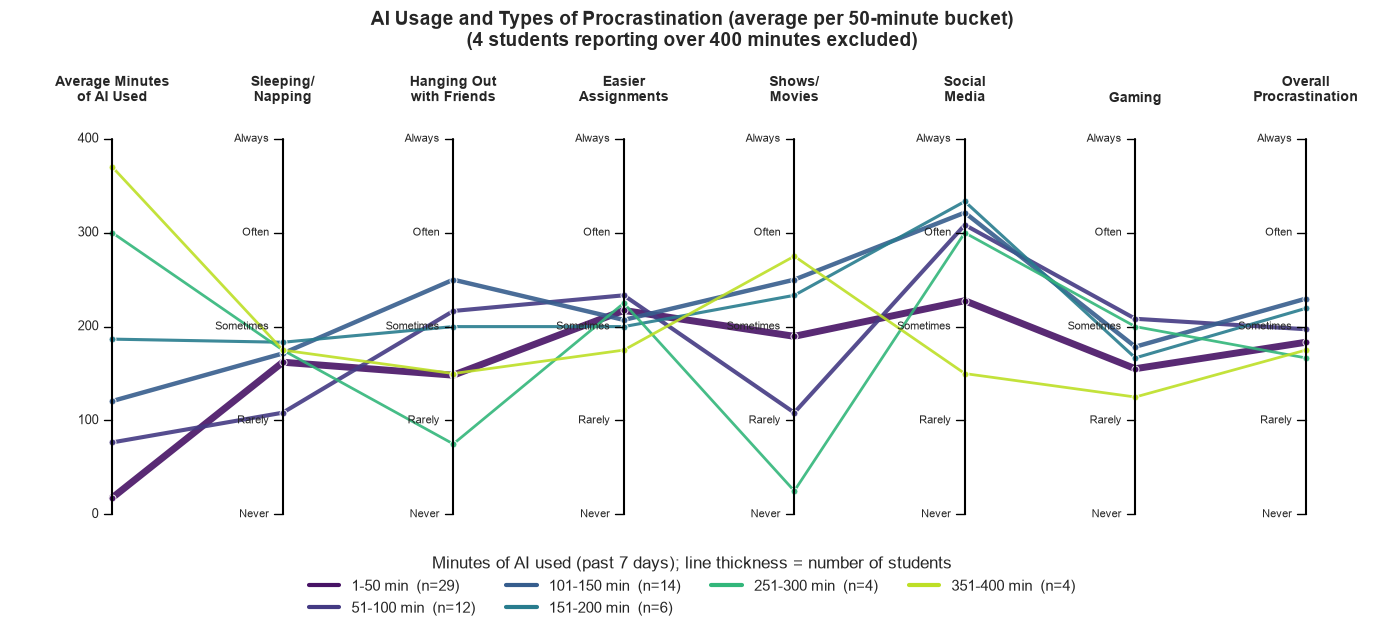

In [17]:
sns.set_theme(style="white", font_scale=1.0)

long_df = (scaled_df[columns].reset_index().melt(id_vars="bucket", var_name="axis", value_name="value"))
long_df["bucket"] = long_df["bucket"].astype(str)
long_df["x"] = long_df["axis"].map(dict(zip(columns, x)))

n_max = bucket_n.max()
bucket_lw = {str(b): 1.5 + 3.5 * bucket_n[b] / n_max for b in bucket_n.index}
palette = {str(b): c for b, c in bucket_colors.items()}

fig, pcp = plt.subplots(figsize=(14, 6.5))
sns.lineplot(data=long_df, x="x", y="value", hue="bucket", palette=palette,
             size="bucket", sizes=bucket_lw, estimator=None, sort=False,
             marker="o", markersize=5, alpha=0.9, legend=False, ax=pcp)

for xi, col in zip(x, columns):
    pcp.plot([xi, xi], [0, 1], color="black", linewidth=1.5)
    pcp.text(xi, 1.09, col, ha="center", va="bottom", fontsize=10, fontweight="bold")

for m in ai_ticks:
    pos = m / ai_cutoff
    pcp.plot([-0.05, 0], [pos, pos], color="black", linewidth=1)
    pcp.text(-0.08, pos, str(m), ha="right", va="center", fontsize=9)

for xi in x[1:]:
    for score, label in enumerate(["Never", "Rarely", "Sometimes", "Often", "Always"]):
        pcp.plot([xi - 0.05, xi], [score / 4, score / 4], color="black", linewidth=1)
        pcp.text(xi - 0.08, score / 4, label, ha="right", va="center", fontsize=8)

pcp.set_xlim(-0.6, len(columns) - 0.6)
pcp.set_ylim(-0.05, 1.2)
pcp.axis("off")
plt.title(f"AI Usage and Types of Procrastination (average per {bucket_size}-minute bucket)\n"
          f"({n_removed} students reporting over {ai_cutoff} minutes excluded)",
          fontsize=14, fontweight="bold", y=1.02)

legend_handles = [Line2D([0], [0], color=palette[str(b)], lw=3, label=f"{b}  (n={bucket_n[b]})") for b in bucket_n.index]
pcp.legend(handles=legend_handles, title="Minutes of AI used (past 7 days); line thickness = number of students",
           loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=4, frameon=False)
plt.tight_layout()
plt.show()

**Analysis:**

We did not find a clear relationship between how much students use AI and how much they procrastinate. The lines for different AI-use groups overlap and cross on every axis, with no group consistently higher or lower. The differences between the highest buckets come from only 3-4 students each, so they are more likely noise than real patterns. What the data does show clearly is that social media is the most common way students procrastinate, regardless of how much they use AI. Additionally students who used more AI were very slightly more likely to report procrastinating. However, there was too small a sample size to make a clear correlation. A larger sample would be needed to rule out a small relationship.